# 07 — Final Evaluation, Comparison and Conclusions
**Member 1 (consolidation).** This is the only notebook that touches the **held-out
test set** (114 samples: 72 benign, 42 malignant). All models, hyper-parameters, PCA
settings and feature subsets were fixed beforehand using 5-fold CV on the training set
(notebooks 01–06). Every model is refitted once on the full training set (455 samples)
and scored once on the test set.

**Selection rule, declared before looking at test results:** the final recommended
model is the configuration with the highest mean CV F1 (malignant class) across *all*
experiments. If several are within 0.002 of each other, the one using the fewest
features wins.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, cross_val_predict
from common import *
from models import build_pipeline, display_name
from feature_selectors import make_selector, METHOD_NAMES

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180, "display.max_columns", 40)
X_train, X_test, y_train, y_test = get_split()
PARAMS = load_best_params()
ALL_MODELS = ["dummy", "lda", "logreg", "gnb", "knn", "svm", "dtree", "rf"]


def make_config(key, method="none", n=30):
    """Rebuild any configuration from the CV experiments."""
    if method == "none":
        reducer = None
    elif method == "PCA":
        n = float(n)
        reducer = PCA(n_components=n if n < 1 else int(n), random_state=RANDOM_STATE)
    else:
        reducer = make_selector(method, int(n))
    return build_pipeline(key, PARAMS[key], reducer=reducer)


def config_label(key, method, n):
    if method == "none":
        return f"{display_name(key)} | all 30"
    if method == "PCA":
        return f"{display_name(key)} | PCA {'95%' if float(n) < 1 else int(float(n))}"
    return f"{display_name(key)} | {METHOD_NAMES[method]} k={int(n)}"

## 1. Cross-validation summary (training set) — all eight models on 30 features

In [2]:
cv_all = pd.concat([pd.read_csv(RESULTS_DIR / f) for f in
                    ["cv_01_baselines.csv", "cv_02_logreg_gnb.csv", "cv_03_knn_svm.csv", "cv_04_trees.csv"]],
                   ignore_index=True)
cv_all = cv_all.set_index("key").loc[ALL_MODELS].reset_index()
summarize(cv_all.to_dict("records"))[["model", "accuracy", "precision", "recall", "specificity", "f1", "roc_auc"]]

,model,accuracy,precision,recall,specificity,f1,roc_auc
0,Majority baseline,0.6264 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000
1,LDA,0.9560 ± 0.0231,0.9935 ± 0.0129,0.8882 ± 0.0600,0.9965 ± 0.0070,0.9369 ± 0.0342,0.9938 ± 0.0041
2,Logistic Regression,0.9758 ± 0.0082,0.9766 ± 0.0215,0.9588 ± 0.0144,0.9860 ± 0.0131,0.9674 ± 0.0109,0.9949 ± 0.0056
3,Gaussian NB,0.9429 ± 0.0273,0.9454 ± 0.0395,0.9000 ± 0.0513,0.9684 ± 0.0233,0.9214 ± 0.0371,0.9867 ± 0.0078
4,KNN,0.9758 ± 0.0162,0.9877 ± 0.0151,0.9471 ± 0.0343,0.9930 ± 0.0086,0.9667 ± 0.0223,0.9834 ± 0.0102
5,SVM,0.9824 ± 0.0112,0.9889 ± 0.0222,0.9647 ± 0.0343,0.9930 ± 0.0140,0.9760 ± 0.0156,0.9951 ± 0.0060
6,Decision Tree,0.9538 ± 0.0224,0.9487 ± 0.0459,0.9294 ± 0.0399,0.9684 ± 0.0302,0.9378 ± 0.0297,0.9745 ± 0.0151
7,Random Forest,0.9692 ± 0.0189,0.9662 ± 0.0396,0.9529 ± 0.0353,0.9789 ± 0.0258,0.9587 ± 0.0249,0.9848 ± 0.0103


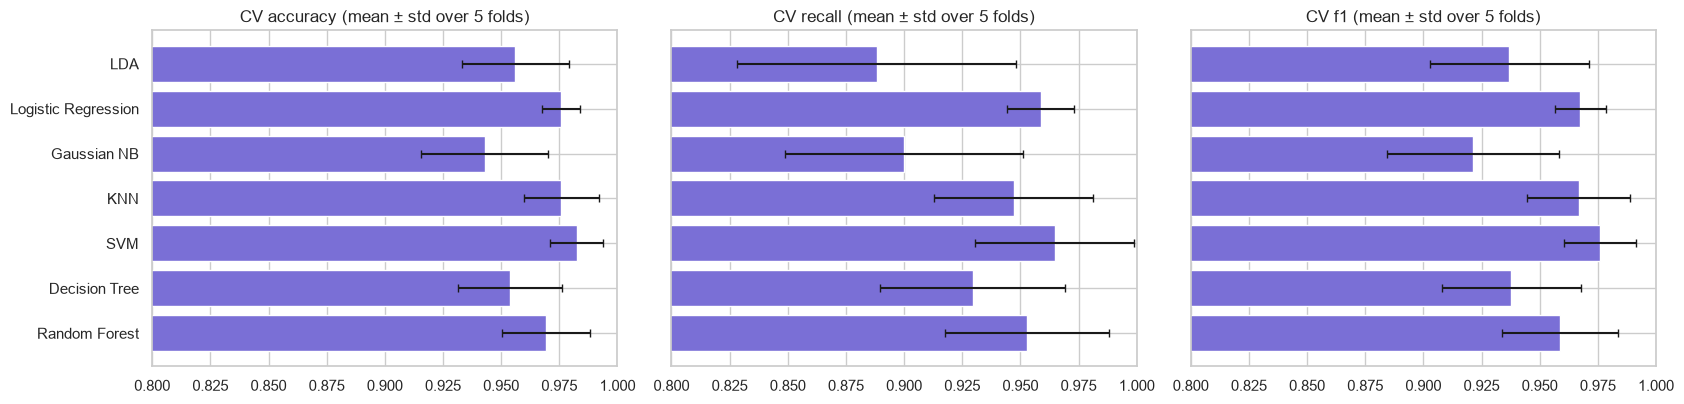

In [3]:
plot_models = [k for k in ALL_MODELS if k != "dummy"]
d = cv_all.set_index("key").loc[plot_models]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, m in zip(axes, ["accuracy", "recall", "f1"]):
    ax.barh([display_name(k) for k in plot_models], d[f"cv_{m}"], xerr=d[f"cv_{m}_std"], color="#7A6FD6", capsize=3)
    ax.set_xlim(0.8, 1.0); ax.set_title(f"CV {m} (mean ± std over 5 folds)")
    ax.invert_yaxis() if ax is axes[0] else None
fig.tight_layout(); savefig(fig, "07_cv_models"); plt.show()

## 2. Test-set results — all eight models on 30 features

In [4]:
fitted, test_rows = {}, []
for key in ALL_MODELS:
    fitted[key] = make_config(key).fit(X_train, y_train)
    test_rows.append(test_evaluate(fitted[key], X_test, y_test, name=display_name(key), key=key, feature_set="all 30"))
test_models = pd.DataFrame(test_rows)
save_rows(test_rows, "test_models_all30.csv")
test_models[["model", "accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "tn", "fp", "fn", "tp"]].round(4)

,model,accuracy,precision,recall,specificity,f1,roc_auc,tn,fp,fn,tp
0,Majority baseline,0.6316,0.0000,0.0000,1.0000,0.0000,0.5000,72,0,42,0
1,LDA,0.9649,1.0000,0.9048,1.0000,0.9500,0.9970,72,0,4,38
2,Logistic Regression,0.9912,1.0000,0.9762,1.0000,0.9880,0.9977,72,0,1,41
3,Gaussian NB,0.9211,0.9231,0.8571,0.9583,0.8889,0.9897,69,3,6,36
4,KNN,0.9649,1.0000,0.9048,1.0000,0.9500,0.9735,72,0,4,38
5,SVM,0.9912,1.0000,0.9762,1.0000,0.9880,0.9974,72,0,1,41
6,Decision Tree,0.9035,0.8974,0.8333,0.9444,0.8642,0.9076,68,4,7,35
7,Random Forest,0.9737,1.0000,0.9286,1.0000,0.9630,0.9927,72,0,3,39


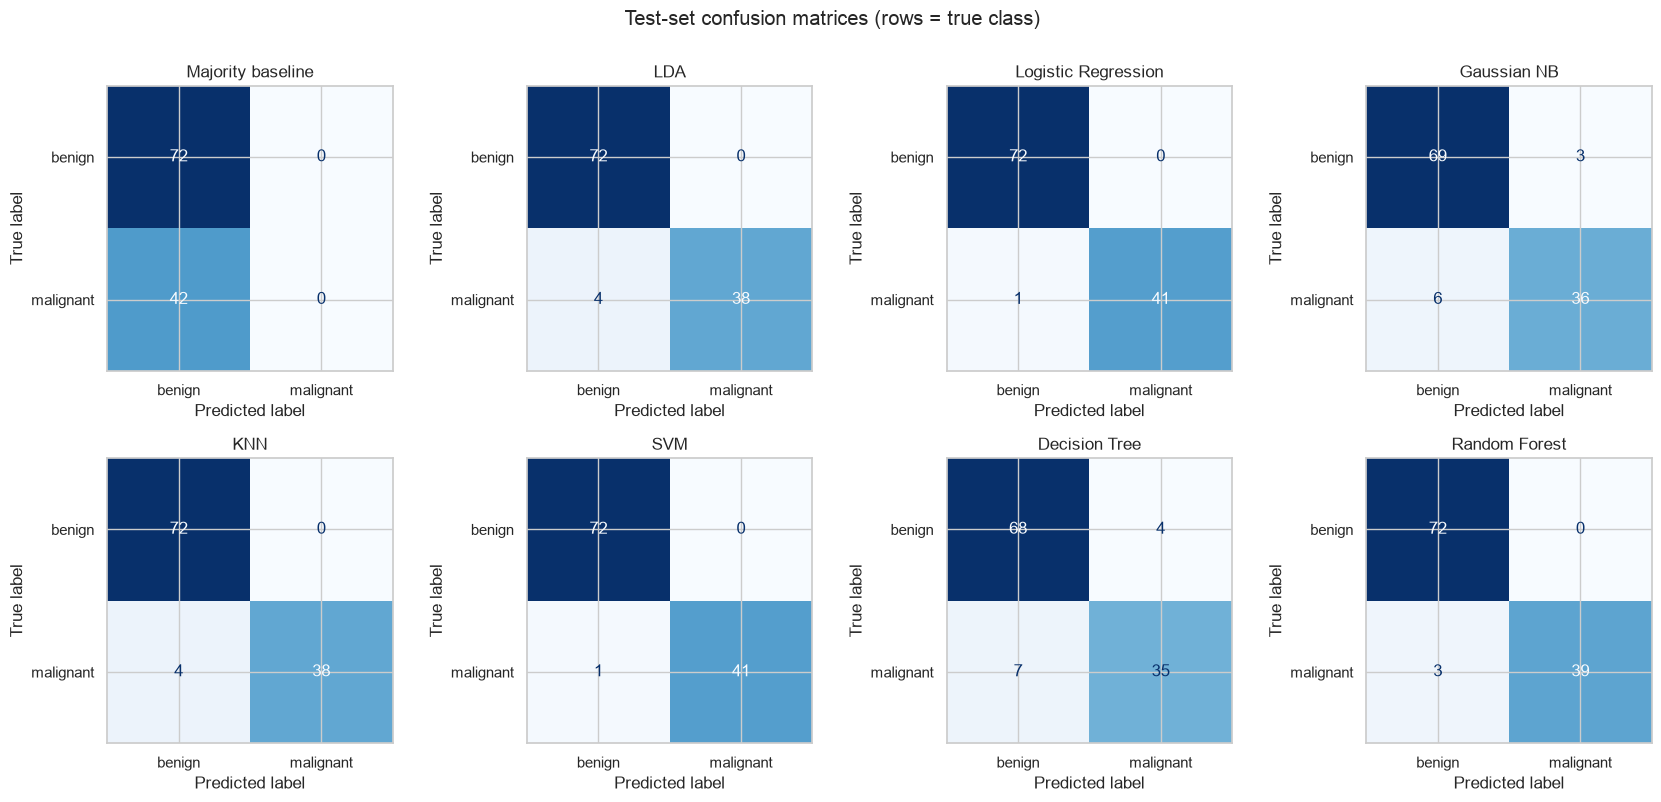

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, key in zip(axes.flat, ALL_MODELS):
    ConfusionMatrixDisplay.from_estimator(fitted[key], X_test, y_test, display_labels=CLASS_NAMES, cmap="Blues",
                                          colorbar=False, ax=ax)
    ax.set_title(display_name(key))
fig.suptitle("Test-set confusion matrices (rows = true class)", y=1.0); fig.tight_layout()
savefig(fig, "07_test_confusion"); plt.show()

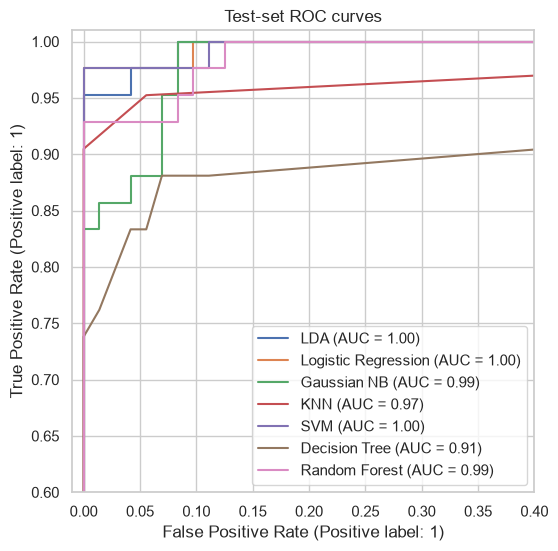

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for key in plot_models:
    RocCurveDisplay.from_estimator(fitted[key], X_test, y_test, name=display_name(key), ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=.8)
ax.set_title("Test-set ROC curves"); ax.set_xlim(-0.01, 0.4); ax.set_ylim(0.6, 1.01)
savefig(fig, "07_test_roc"); plt.show()

In [7]:
cmp = cv_all.set_index("model")[["cv_accuracy", "cv_recall", "cv_f1"]].join(
    test_models.set_index("model")[["accuracy", "recall", "f1"]].add_prefix("test_"))
cmp.round(4)

,cv_accuracy,cv_recall,cv_f1,test_accuracy,test_recall,test_f1
model,,,,,,
Majority baseline,0.6264,0.0000,0.0000,0.6316,0.0000,0.0000
LDA,0.9560,0.8882,0.9369,0.9649,0.9048,0.9500
Logistic Regression,0.9758,0.9588,0.9674,0.9912,0.9762,0.9880
Gaussian NB,0.9429,0.9000,0.9214,0.9211,0.8571,0.8889
KNN,0.9758,0.9471,0.9667,0.9649,0.9048,0.9500
SVM,0.9824,0.9647,0.9760,0.9912,0.9762,0.9880
Decision Tree,0.9538,0.9294,0.9378,0.9035,0.8333,0.8642
Random Forest,0.9692,0.9529,0.9587,0.9737,0.9286,0.9630


**Test results agree with CV.** Logistic Regression and the RBF SVM are the best models
on the test set, with identical results: 113/114 correct, **one missed malignant tumour
and no false positives** (recall 0.976, specificity 1.0). Random Forest misses 3, and LDA
and KNN miss 4 each. Gaussian NB and the Decision Tree are clearly weakest, which matches
their CV ranking. KNN drops more from CV to test than the other models (recall
0.947 → 0.905), which is within the noise expected from a 42-case malignant test set.

**Note on test-set resolution.** With only 42 malignant test cases, each missed cancer
lowers test recall by 2.4 points, and each error of any kind lowers accuracy by 0.9 points.
Differences of one or two errors between the top models are within noise, so we lean on
CV (and repeated CV, section 5) to rank models, and use the test set to confirm that
CV estimates generalise.

## 3. Reduced representations — PCA and feature selection on the test set

In [8]:
pca_cv = pd.read_csv(RESULTS_DIR / "cv_05_pca.csv")
pca_cv = pca_cv[pca_cv.method == "PCA"].assign(n=lambda d: d["n_components"].astype(str))
fs_cv = pd.read_csv(RESULTS_DIR / "cv_06_feature_selection.csv")
fs_cv = fs_cv[fs_cv.method != "none"].assign(n=lambda d: d["n_features"].astype(str))
base_cv = cv_all[cv_all.key != "dummy"].assign(method="none", n="30", n_features=30)
configs = pd.concat([base_cv, pca_cv, fs_cv], ignore_index=True)
configs["n_features"] = configs["n_features"].astype(int)
# "PCA 95%" selects exactly 10 components here, i.e. the same model as "PCA 10": keep one copy
configs = configs.drop_duplicates(subset=["key", "method", "n_features"])
configs["n"] = np.where(configs.method == "PCA", configs.n_features.astype(str), configs.n)
configs["label"] = [config_label(k, m, n) for k, m, n in zip(configs.key, configs.method, configs.n)]

red_rows = []
for _, c in configs[configs.method != "none"].iterrows():
    mdl = make_config(c.key, c.method, c.n).fit(X_train, y_train)
    red_rows.append(test_evaluate(mdl, X_test, y_test, name=c.label, key=c.key, method=c.method,
                                  n_features=int(c.n_features), cv_f1=c.cv_f1, cv_recall=c.cv_recall))
red = pd.DataFrame(red_rows)
save_rows(red_rows, "test_reduced.csv")
red.sort_values(["method", "key", "n_features"])[
    ["model", "n_features", "cv_f1", "cv_recall", "accuracy", "recall", "specificity", "f1", "roc_auc", "fn", "fp"]].round(4)

,model,n_features,cv_f1,cv_recall,accuracy,recall,specificity,f1,roc_auc,fn,fp
45,Gaussian NB | L1 path k=5,5,0.9395,0.9176,0.9386,0.8810,0.9722,0.9136,0.9950,5,2
46,Gaussian NB | L1 path k=10,10,0.9386,0.9059,0.9474,0.8810,0.9861,0.9250,0.9967,5,1
47,Gaussian NB | L1 path k=15,15,0.9156,0.8941,0.9474,0.8810,0.9861,0.9250,0.9947,5,1
27,KNN | L1 path k=5,5,0.9415,0.9118,0.9474,0.8810,0.9861,0.9250,0.9727,5,1
28,KNN | L1 path k=10,10,0.9537,0.9235,0.9649,0.9048,1.0000,0.9500,0.9974,4,0
29,KNN | L1 path k=15,15,0.9507,0.9176,0.9474,0.8571,1.0000,0.9231,0.9474,6,0
18,Logistic Regression | L1 path k=5,5,0.9647,0.9647,0.9649,0.9524,0.9722,0.9524,0.9967,2,2
19,Logistic Regression | L1 path k=10,10,0.9551,0.9412,0.9825,0.9524,1.0000,0.9756,0.9980,2,0
20,Logistic Regression | L1 path k=15,15,0.9519,0.9353,0.9825,0.9524,1.0000,0.9756,0.9983,2,0
36,SVM | L1 path k=5,5,0.9612,0.9529,0.9737,0.9524,0.9861,0.9639,0.9960,2,1


## 4. Performance vs number of features: PCA vs feature selection
CV curves from notebooks 05 and 06. At equal dimensionality, PCA uses information from
all 30 measurements, while feature selection uses only *k* of them.

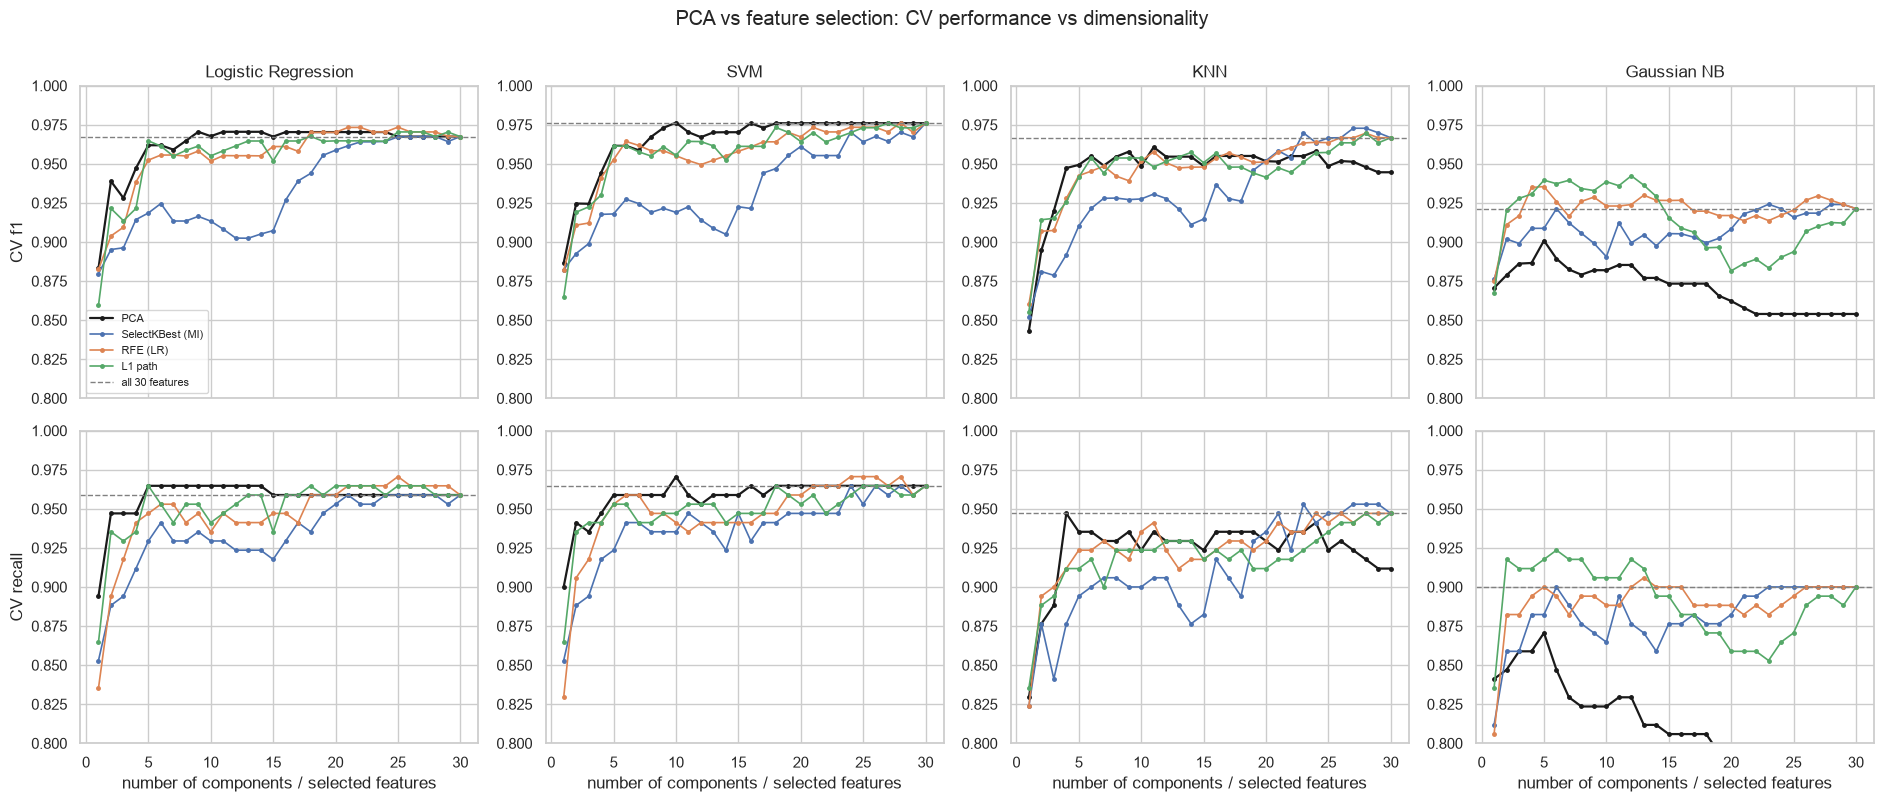

In [9]:
pca_curve = pd.read_csv(RESULTS_DIR / "cv_05_pca_curve.csv").assign(method="PCA")
fs_curve = pd.read_csv(RESULTS_DIR / "cv_06_fs_curve.csv")
curves = pd.concat([pca_curve, fs_curve], ignore_index=True)
labels = {"PCA": "PCA", **METHOD_NAMES}
fig, axes = plt.subplots(2, 4, figsize=(19, 8), sharex=True)
for j, key in enumerate(["logreg", "svm", "knn", "gnb"]):
    for i, m in enumerate(["f1", "recall"]):
        ax = axes[i, j]
        for method, style in [("PCA", "k-"), ("MI", "-"), ("RFE", "-"), ("L1", "-")]:
            g = curves[(curves.key == key) & (curves.method == method)]
            ax.plot(g["n_features"], g[f"cv_{m}"], style, marker="o", ms=2.5, lw=1.6 if method == "PCA" else 1.2,
                    label=labels[method])
        ref = cv_all.set_index("key").loc[key, f"cv_{m}"]
        ax.axhline(ref, color="grey", ls="--", lw=1, label="all 30 features")
        ax.set_ylim(0.8, 1.0)
        if i == 0: ax.set_title(display_name(key))
        if i == 1: ax.set_xlabel("number of components / selected features")
        if j == 0: ax.set_ylabel(f"CV {m}")
axes[0, 0].legend(fontsize=8)
fig.suptitle("PCA vs feature selection: CV performance vs dimensionality", y=1.0); fig.tight_layout()
savefig(fig, "07_pca_vs_fs_curves"); plt.show()

In [10]:
def min_k(g, ref, tol=0.01):
    ok = g[g["cv_f1"] >= ref - tol]
    return int(ok["n_features"].min()) if len(ok) else np.nan

tab = []
for key in ["logreg", "svm", "knn", "gnb"]:
    ref = cv_all.set_index("key").loc[key, "cv_f1"]
    row = {"model": display_name(key), "all30_cv_f1": ref}
    for method in ["PCA", "MI", "RFE", "L1"]:
        g = curves[(curves.key == key) & (curves.method == method)]
        row[f"{labels[method]}: min dims within 0.01"] = min_k(g, ref)
        row[f"{labels[method]}: F1 @5"] = g[g.n_features == 5]["cv_f1"].iloc[0]
    tab.append(row)
tab = pd.DataFrame(tab).set_index("model")
tab.to_csv(RESULTS_DIR / "pca_vs_fs_summary.csv")
tab.round(4).T

model,Logistic Regression,SVM,KNN,Gaussian NB
all30_cv_f1,0.9674,0.9760,0.9667,0.9214
PCA: min dims within 0.01,5.0000,8.0000,9.0000,NaN
PCA: F1 @5,0.9619,0.9615,0.9493,0.9009
SelectKBest (MI): min dims within 0.01,20.0000,24.0000,21.0000,6.0000
SelectKBest (MI): F1 @5,0.9186,0.9179,0.9102,0.9088
RFE (LR): min dims within 0.01,9.0000,19.0000,11.0000,3.0000
RFE (LR): F1 @5,0.9524,0.9527,0.9425,0.9355
L1 path: min dims within 0.01,5.0000,18.0000,14.0000,2.0000
L1 path: F1 @5,0.9647,0.9612,0.9415,0.9395


## 5. Robustness: repeated cross-validation of the top configurations
The 5-fold CV estimates above come from a single split into folds. To see whether the
small differences between the leading configurations are real, the top 8 configurations
(by CV F1) are re-evaluated with **10 × repeated 5-fold stratified CV** (50 fits each)
on the training set.

In [11]:
top = configs.sort_values("cv_f1", ascending=False).head(8)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
rep_rows, rep_scores = [], {}
for _, c in top.iterrows():
    res = cross_validate(make_config(c.key, c.method, c.n), X_train, y_train, cv=rcv, scoring=SCORING, n_jobs=-1)
    rep_scores[c.label] = res["test_f1"]
    row = {"configuration": c.label, "n_features": int(c.n_features), "cv5_f1": c.cv_f1}
    for m in ["accuracy", "recall", "specificity", "f1", "roc_auc"]:
        row[f"rep_{m}"] = res[f"test_{m}"].mean(); row[f"rep_{m}_std"] = res[f"test_{m}"].std()
    rep_rows.append(row)
rep = pd.DataFrame(rep_rows).sort_values("rep_f1", ascending=False)
save_rows(rep_rows, "repeated_cv_top.csv")
rep[["configuration", "n_features", "cv5_f1", "rep_f1", "rep_f1_std", "rep_recall", "rep_specificity", "rep_accuracy", "rep_roc_auc"]].round(4)

,configuration,n_features,cv5_f1,rep_f1,rep_f1_std,rep_recall,rep_specificity,rep_accuracy,rep_roc_auc
3,Logistic Regression | all 30,30,0.9674,0.9667,0.0204,0.9600,0.9846,0.9754,0.9937
2,Logistic Regression | PCA 10,10,0.9677,0.9665,0.0211,0.9600,0.9842,0.9752,0.9933
0,SVM | PCA 10,10,0.9764,0.9656,0.0218,0.9588,0.9839,0.9745,0.9950
1,SVM | all 30,30,0.9760,0.9645,0.0225,0.9553,0.9849,0.9738,0.9949
7,SVM | PCA 5,5,0.9615,0.9594,0.0235,0.9553,0.9786,0.9699,0.9944
6,Logistic Regression | PCA 5,5,0.9619,0.9592,0.0247,0.9553,0.9782,0.9697,0.9938
5,Logistic Regression | L1 path k=5,5,0.9647,0.9584,0.0219,0.9571,0.9761,0.9690,0.9904
4,KNN | all 30,30,0.9667,0.9564,0.0266,0.9318,0.9905,0.9686,0.9768


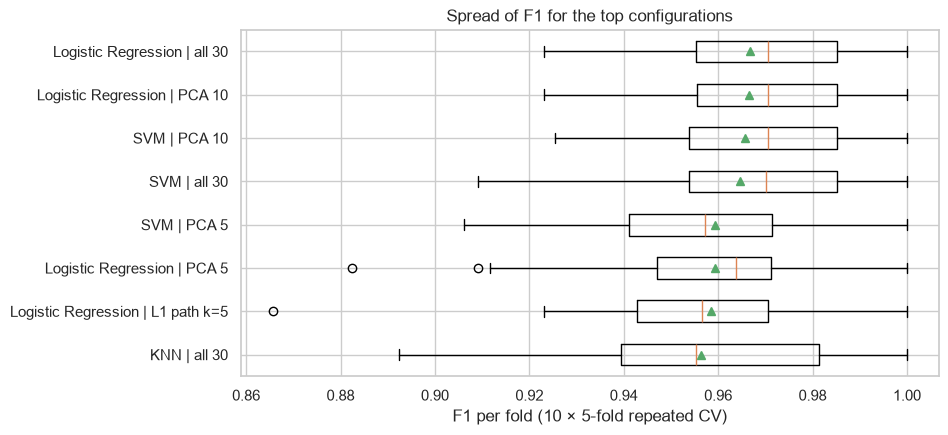

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = rep["configuration"].tolist()
ax.boxplot([rep_scores[o] for o in order], orientation="horizontal", tick_labels=order, showmeans=True)
ax.invert_yaxis(); ax.set_xlabel("F1 per fold (10 × 5-fold repeated CV)")
ax.set_title("Spread of F1 for the top configurations")
savefig(fig, "07_repeated_cv_box"); plt.show()

The boxes overlap almost completely. Under repeated CV the ranking even reshuffles:
logistic regression (all 30 or 10 PCs) edges ahead of the RBF SVM, and all are within
0.002 F1 of each other. The fold-to-fold spread (std ≈ 0.020–0.027 F1) is about ten times
larger than the gaps between their means. **The top linear and RBF models, with 30
features or 10 PCs, are statistically indistinguishable on this dataset.** Even LR with
only 5 L1-selected features is within ≈0.008 F1.

## 6. Final recommended model (rule declared at the top)

In [13]:
ranked = configs.sort_values("cv_f1", ascending=False)
best_f1 = ranked["cv_f1"].iloc[0]
near = ranked[ranked["cv_f1"] >= best_f1 - 0.002].sort_values(["n_features", "cv_f1"], ascending=[True, False])
final_cfg = near.iloc[0]
print("Configurations within 0.002 CV-F1 of the best:")
print(near[["label", "n_features", "cv_f1", "cv_recall"]].round(4).to_string(index=False))
print("\nFINAL MODEL:", final_cfg.label, f"(CV F1 = {final_cfg.cv_f1:.4f})")
final = make_config(final_cfg.key, final_cfg.method, final_cfg.n).fit(X_train, y_train)
final_test = test_evaluate(final, X_test, y_test, name=final_cfg.label)
pd.Series(final_test)

Configurations within 0.002 CV-F1 of the best:
       label  n_features  cv_f1  cv_recall
SVM | PCA 10          10 0.9764     0.9706
SVM | all 30          30 0.9760     0.9647

FINAL MODEL: SVM | PCA 10 (CV F1 = 0.9764)


model          SVM | PCA 10
accuracy           0.982456
precision               1.0
recall             0.952381
specificity             1.0
f1                  0.97561
roc_auc            0.997685
tn                       72
fp                        0
fn                        2
tp                       40
dtype: object

In [14]:
rng = np.random.default_rng(RANDOM_STATE)
y_pred = final.predict(X_test)
y_score = final.decision_function(X_test) if hasattr(final, "decision_function") else final.predict_proba(X_test)[:, 1]
boot = []
yt = y_test.values
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[idx])) < 2:
        continue
    boot.append(compute_metrics(yt[idx], y_pred[idx], y_score[idx]))
boot = pd.DataFrame(boot)
ci = pd.DataFrame({"test value": pd.Series(final_test)[METRICS].astype(float),
                   "95% CI low": boot[METRICS].quantile(0.025), "95% CI high": boot[METRICS].quantile(0.975)})
ci.round(4)

,test value,95% CI low,95% CI high
accuracy,0.9825,0.9561,1.0
precision,1.0000,1.0000,1.0
recall,0.9524,0.8750,1.0
specificity,1.0000,1.0000,1.0
f1,0.9756,0.9333,1.0
roc_auc,0.9977,0.9910,1.0


## 7. Prioritising malignant recall: moving the decision threshold
A false negative (a malignant tumour called benign) is far more costly than a false
positive, which only leads to a follow-up test. Instead of the default threshold, we can
choose one that targets a higher sensitivity. To avoid using the test set, the threshold
is chosen from **out-of-fold** scores on the training set. We pick the highest threshold
whose out-of-fold malignant recall is ≥ 0.99, then apply it unchanged to the test set.

In [15]:
method = "decision_function" if hasattr(final, "decision_function") else "predict_proba"
oof = cross_val_predict(make_config(final_cfg.key, final_cfg.method, final_cfg.n), X_train, y_train,
                        cv=get_cv(), method=method)
oof = oof if oof.ndim == 1 else oof[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
default_thr = 0.0 if method == "decision_function" else 0.5
ok = np.where(rec[:-1] >= 0.99)[0]
chosen_thr = thr[ok].max()
print(f"default threshold: {default_thr}, chosen threshold (OOF recall ≥ 0.99): {chosen_thr:.4f}")

rows = []
for name, t in [("default threshold", default_thr), ("high-sensitivity threshold", chosen_thr)]:
    rows.append({"setting": name, "threshold": t, "split": "train OOF",
                 **compute_metrics(y_train, (oof >= t).astype(int), oof)})
    rows.append({"setting": name, "threshold": t, "split": "TEST",
                 **compute_metrics(y_test, (y_score >= t).astype(int), y_score)})
thr_df = pd.DataFrame(rows)
save_rows(rows, "threshold_analysis.csv")
thr_df[["setting", "split", "threshold", "accuracy", "precision", "recall", "specificity", "f1", "fn", "fp"]].round(4)

default threshold: 0.0, chosen threshold (OOF recall ≥ 0.99): -0.9691


,setting,split,threshold,accuracy,precision,recall,specificity,f1,fn,fp
0,default threshold,train OOF,0.0000,0.9824,0.9821,0.9706,0.9895,0.9763,5,3
1,default threshold,TEST,0.0000,0.9825,1.0000,0.9524,1.0000,0.9756,2,0
2,high-sensitivity threshold,train OOF,-0.9691,0.9077,0.8048,0.9941,0.8561,0.8895,1,41
3,high-sensitivity threshold,TEST,-0.9691,0.9298,0.8400,1.0000,0.8889,0.9130,0,8


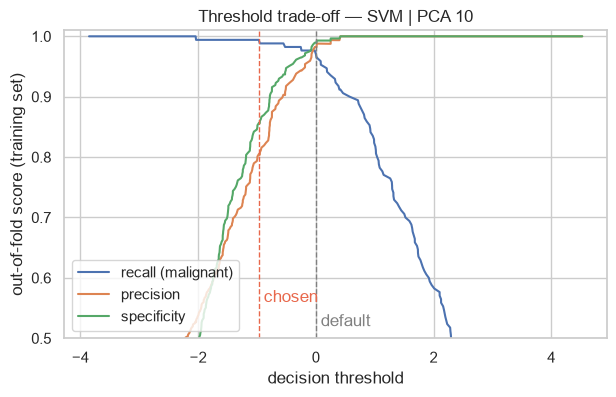

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr, rec[:-1], label="recall (malignant)"); ax.plot(thr, prec[:-1], label="precision")
spec = [specificity_score(y_train, (oof >= t).astype(int)) for t in thr]
ax.plot(thr, spec, label="specificity")
ax.axvline(default_thr, color="grey", ls="--", lw=1); ax.text(default_thr, 0.52, " default", color="grey")
ax.axvline(chosen_thr, color="#E8684C", ls="--", lw=1); ax.text(chosen_thr, 0.56, " chosen", color="#E8684C")
ax.set_xlabel("decision threshold"); ax.set_ylabel("out-of-fold score (training set)"); ax.set_ylim(0.5, 1.01)
ax.set_title(f"Threshold trade-off — {final_cfg.label}"); ax.legend(loc="lower left")
savefig(fig, "07_threshold_tradeoff"); plt.show()

## 8. Error analysis on the test set
Which test tumours are misclassified, and by how many of the seven non-trivial models?

In [17]:
preds = pd.DataFrame({display_name(k): fitted[k].predict(X_test) for k in plot_models}, index=X_test.index)
wrong = preds.ne(y_test, axis=0)
summary = pd.DataFrame({"true": y_test.map({0: "benign", 1: "malignant"}), "n_models_wrong": wrong.sum(axis=1)})
hard = summary[summary.n_models_wrong > 0].join(preds).join(
    X_test[["radius_worst", "perimeter_worst", "concave_points_worst", "texture_worst"]])
hard = hard.sort_values("n_models_wrong", ascending=False)
hard.to_csv(RESULTS_DIR / "test_error_analysis.csv")
print("test samples misclassified by ≥1 model:", len(hard), "| by ≥4 models:", int((hard.n_models_wrong >= 4).sum()))
hard.round(3)

test samples misclassified by ≥1 model: 17 | by ≥4 models: 3


,true,n_models_wrong,LDA,Logistic Regression,Gaussian NB,KNN,SVM,Decision Tree,Random Forest,radius_worst,perimeter_worst,concave_points_worst,texture_worst
73,malignant,7,0,0,0,0,0,0,0,16.57,110.30,0.138,20.86
86,malignant,4,0,1,0,1,1,0,0,16.21,108.40,0.122,29.25
385,malignant,4,1,1,0,0,1,0,0,15.79,102.20,0.136,31.71
205,malignant,2,1,1,0,0,1,1,1,17.77,117.70,0.125,20.24
39,malignant,2,0,1,1,0,1,1,1,15.53,107.30,0.226,26.02
128,benign,2,0,0,1,0,0,1,0,16.11,105.90,0.142,18.33
100,malignant,2,1,1,0,1,1,0,1,16.99,108.60,0.118,35.27
5,malignant,1,1,1,1,1,1,0,1,15.47,103.40,0.174,23.75
440,benign,1,0,0,0,0,0,1,0,12.36,90.14,0.156,26.87
190,malignant,1,0,1,1,1,1,1,1,15.74,106.40,0.177,37.18


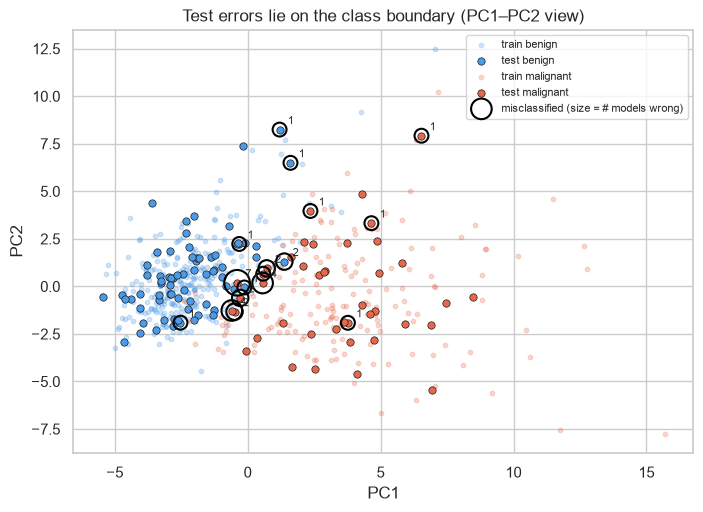

In [18]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(X_train); p2 = PCA(2).fit(sc.transform(X_train))
P_tr, P_te = p2.transform(sc.transform(X_train)), p2.transform(sc.transform(X_test))
fig, ax = plt.subplots(figsize=(8, 5.5))
for lab, col in [(0, "#4C9BE8"), (1, "#E8684C")]:
    m = y_train.values == lab
    ax.scatter(P_tr[m, 0], P_tr[m, 1], s=10, alpha=.25, c=col, label=f"train {CLASS_NAMES[lab]}")
    m = y_test.values == lab
    ax.scatter(P_te[m, 0], P_te[m, 1], s=28, c=col, edgecolor="k", lw=.5, label=f"test {CLASS_NAMES[lab]}")
nw = summary["n_models_wrong"].values
m = nw > 0
sca = ax.scatter(P_te[m, 0], P_te[m, 1], s=60 + 40 * nw[m], facecolor="none", edgecolor="black", lw=1.5,
                 label="misclassified (size = # models wrong)")
for (x, yv), n in zip(P_te[m], nw[m]):
    ax.annotate(str(n), (x, yv), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=8, loc="upper right")
ax.set_title("Test errors lie on the class boundary (PC1–PC2 view)")
savefig(fig, "07_error_map"); plt.show()

## 9. Interpretability vs performance

In [19]:
interp = pd.DataFrame([
    ["Decision Tree", "all 30 (tree uses 12)", "High: readable if-then rules", "dtree", "none", 30],
    ["Logistic Regression", "all 30", "High: one signed weight per feature", "logreg", "none", 30],
    ["LDA", "all 30", "Medium-high: linear discriminant weights", "lda", "none", 30],
    ["Gaussian NB", "all 30", "Medium: per-feature class likelihoods", "gnb", "none", 30],
    ["Random Forest", "all 30", "Low-medium: aggregate importances only", "rf", "none", 30],
    ["KNN", "all 30", "Low: explanation by similar cases", "knn", "none", 30],
    ["SVM (RBF)", "all 30", "Low: non-linear kernel", "svm", "none", 30],
    ["SVM (RBF) + PCA 10", "all 30 measured, 10 PCs used", "Very low: kernel on mixed components", "svm", "PCA", 10],
    ["SVM (RBF) + RFE 10", "10 measured", "Low, but needs only 10 named measurements", "svm", "RFE", 10],
    ["Logistic Regression + L1 path 10", "10 measured", "High: 10 named features, 10 weights", "logreg", "L1", 10],
], columns=["model", "features that must be measured", "interpretability", "key", "method", "n"])
lookup = configs.set_index(["key", "method", "n_features"])["cv_f1"]
interp["cv_f1 (reused params)"] = [lookup.get((k, m, n), np.nan) for k, m, n in zip(interp.key, interp.method, interp.n)]
interp.drop(columns=["key", "method", "n"]).round(4)

,model,features that must be measured,interpretability,cv_f1 (reused params)
0,Decision Tree,all 30 (tree uses 12),High: readable if-then rules,0.9378
1,Logistic Regression,all 30,High: one signed weight per feature,0.9674
2,LDA,all 30,Medium-high: linear discriminant weights,0.9369
3,Gaussian NB,all 30,Medium: per-feature class likelihoods,0.9214
4,Random Forest,all 30,Low-medium: aggregate importances only,0.9587
5,KNN,all 30,Low: explanation by similar cases,0.9667
6,SVM (RBF),all 30,Low: non-linear kernel,0.9760
7,SVM (RBF) + PCA 10,"all 30 measured, 10 PCs used",Very low: kernel on mixed components,0.9764
8,SVM (RBF) + RFE 10,10 measured,"Low, but needs only 10 named measurements",0.9552
9,Logistic Regression + L1 path 10,10 measured,"High: 10 named features, 10 weights",0.9551


## 10. Answers to the research questions

**1. Which classifier performs best on the 30 original features?** The RBF SVM has the
highest CV F1 (0.976; accuracy 0.982), with Logistic Regression close behind (0.967).
Both get 113/114 test samples right (one false negative, no false positives).
Repeated CV shows the two are statistically tied. Gaussian NB and the single Decision
Tree are the weakest; the majority baseline finds no cancers at all.

**2. Does PCA improve or reduce performance?** Neither, at the right size. Ten components
(95 % variance) match the 30-feature models for LR and SVM (SVM CV F1 0.976 → 0.976,
recall 0.965 → 0.971). Five components cost ≈1 F1 point, and two components cost 3–7
points. PCA hurts Gaussian NB.

**3. How many components are sufficient?** 5 for LR, 8 for SVM, and 9 for KNN (within 0.01
F1 of all 30). About 10 is the practical sweet spot.

**4. Can feature selection match the full set with far fewer features?** Yes, with a
multivariate selector. LR on **5 L1-path features** reaches CV F1 0.965 vs 0.967. After
re-tuning, LR or a linear SVM on 10 L1-selected features reaches ≈0.97. The univariate
MI filter fails: it picks redundant size features and stays 4–6 points below even at
k = 15.

**5. Which measurements are consistently important?** `radius_worst`,
`perimeter_worst`, `area_worst`, `concave_points_worst` and `concave_points_mean`,
followed by `texture_worst` and `radius_se`. Every method agrees: tree importances,
all three selectors, LR coefficients and PCA loadings.

**6. PCA vs feature selection?** At the same dimensionality, PCA is equal or better for
LR and SVM, most clearly at very low dimension (2–4) and for the SVM at 8–15 dimensions,
because each component pools information from all 30 measurements. For KNN the two are
similar, and for Gaussian NB selection is far better. But PCA still needs all 30 measurements and yields uninterpretable
components. Feature selection keeps named clinical measurements, only those need to be
collected, and for linear models it is just as accurate with 5–10 features.

**7. The trade-off.** On this dataset accuracy is close to saturated, so the real choice
is about interpretability and cost. **Logistic Regression on ~5–10 L1-selected
features** gives near-best performance with a model that can be read and audited.
The formally selected model (RBF SVM + PCA 10) is at most ≈0.01 F1 better and is a
black box. For malignant detection, moving the decision threshold matters far more than
the choice of model: it raised test recall to 1.0 at the cost of 8 false positives.